___
# <font color= #bbc28d> **CNN con recortes segmentados y a color** </font>
#### <font color= #7aa8a7> `Proyecto final · Red Neuronal desde CERO`</font>
- <Strong> Diana Valdivia </Strong> · ITESO

___

Ya contamos con los datos procesados, y con las hipótesis planteadas, sin embargo, debemos de tener un baseline para comprobar si son reales, además de que también sirve como un punto de comparación con modelos un poco mas complejos, si es que hay una gran diferencia entre ellos y si vale la pena los recursos extras que se necesitarían.

1. Primero se entrena una red neuronal con los recortes de las hojas de `segmentación`, para poder tener un punto de referencia.
2. Luego se entrena **la misma red, con los mismos parámetros**, pero con recortes de las fotos `color` tomados de **cualquier posición**, sin quitar fondo ni telón.
3. Finalmente, una **evaluación cruzada**: cada modelo se prueba con el tipo de recortes del otro.

Como lo único que cambia es el tipo de datos, cualquier diferencia se debe a los datos y no al modelo.

# **<font color= #7aa8a7> Parte 1: la variante segmentada </font>**
Empezaremos utilizando las fotos `segmentadas`, para tener un acceso a mejores equipos de computo, el entrenamiento se realizó en Google Colab, montando el DRIVE para guardar los pesos aunque Colab se desconecte, se fijan los parámetros y se establece que se utilizará la GPU para el entrenamiento.

In [ ]:
# Librerías
from google.colab import drive
drive.mount("/content/drive")

import random, subprocess, time, json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import torch, torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms as T
from sklearn.metrics import f1_score, recall_score, confusion_matrix

WORK = Path("/content/maize_work") # Carpeta local de collab
IMG_DIR = WORK / "raw_segmented"
OUT = Path("/content/drive/MyDrive/maize_out") # checkpoints
OUT.mkdir(parents=True, exist_ok=True)

PATCH = 96
IMG_SIZE = 96
EVAL_K = 8
BATCH = 128 
EPOCHS = 30
PATIENCE = 8
SEED = 42
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
print("dispositivo:", DEVICE, "| torch", torch.__version__)
assert DEVICE == "cuda", "Activa la GPU: Entorno de ejecución > Cambiar tipo de entorno"

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
dispositivo: cuda | torch 2.14.1+cu130


# **<font color= #7aa8a7> Datos </font>**
Se lee el split y el índice de recortes del EDA, y se revisa con `assert` que los recortes sean de 96 px, que existan las imágenes y que **ningún grupo quede en dos conjuntos**.

In [ ]:
# Descomprimir zip de split
ZIP = "/content/drive/MyDrive/maize_data.zip" 
if not IMG_DIR.exists():
    subprocess.run(["unzip", "-q", "-o", ZIP, "-d", str(WORK)], check=True)

meta = pd.read_csv(WORK / "split_v1.csv")
idx = pd.read_csv(WORK / "patch_index_v1.csv")
meta["path"] = [str(IMG_DIR / l / k.split("/")[-1]) for l, k in zip(meta["label"], meta["seg_key"])]

CLASSES = sorted(meta["label"].unique())
CLASS_TO_ID = {c: i for i, c in enumerate(CLASSES)}

boxes = {k: g[["y", "x"]].to_numpy() for k, g in idx.groupby("seg_key")}
meta["n_patch"] = meta["seg_key"].map(lambda k: len(boxes.get(k, [])))

assert (idx["size"] == PATCH).all(), "El índice debe ser de 96 px"
assert all(Path(p).exists() for p in meta["path"]), "Faltan imágenes locales"
assert (meta.groupby("group")["split"].nunique() == 1).all(), "Hay grupos en más de un split"

usable = meta[meta["n_patch"] > 0].reset_index(drop=True)
train_df = usable[usable["split"] == "train"].reset_index(drop=True)
val_df = usable[usable["split"] == "val"].reset_index(drop=True)
test_df = usable[usable["split"] == "test"].reset_index(drop=True)

print("Imágenes usables por clase y split:")
print(pd.crosstab(usable["label"], usable["split"])[["train", "val", "test"]])
print("\nSin recorte (no se usan):")
print(pd.crosstab(meta[meta.n_patch == 0]["label"], meta[meta.n_patch == 0]["split"]))

Saving maize_color.zip to maize_color.zip
Mismas imágenes que en segmented: 2611 559 559


Quedan **2,611 / 559 / 559** imágenes usables en train / val / test. Las **123** que no tienen ningún recorte sin negro no se usan (80 de `northern_blight`, 24 de `gray_leaf_spot`, 15 de `common_rust` y 4 de `healthy`), por lo que el modelo se evalúa sobre las imágenes con tejido limpio disponible.

# **<font color= #7aa8a7> Aumentos de datos </font>**
Se realiza solo en el set de entrenamiento:
- **Giros de 90° y espejos:** no generan esquinas vacías (una rotación libre sí, y la red podría usarlas de pista).
- **Recorte aleatorio** dentro de un recorte ya limpio: sigue sin negro.
- **Brillo, contraste y saturación:** simulan otras cámaras y luz, pero casi no se mueve el tono porque el color de la lesión es parte de la señal.
- **Desenfoque leve:** evita que la nitidez delate la clase.

En entrenamiento se usa **un recorte al azar por imagen en cada época**; en validación y test, hasta 8 recortes fijos.

In [ ]:
# Definir normalizaciones
MEAN, STD = (0.485, 0.456, 0.406), (0.229, 0.224, 0.225)

class Rot90:
    def __call__(self, img):
        k = random.randint(0, 3)
        return img.rotate(90 * k) if k else img # Imagenes cuadradas

train_tf = T.Compose([
    Rot90(), T.RandomHorizontalFlip(), T.RandomVerticalFlip(),
    T.RandomResizedCrop(IMG_SIZE, scale=(0.6, 1.0), ratio=(1.0, 1.0)),
    T.ColorJitter(0.25, 0.25, 0.2, 0.02),
    T.RandomApply([T.GaussianBlur(5, sigma=(0.1, 1.5))], p=0.3),
    T.ToTensor(), T.Normalize(MEAN, STD),
])
eval_tf = T.Compose([T.Resize(IMG_SIZE), T.ToTensor(), T.Normalize(MEAN, STD)])   # sin aumentos

class PatchDataset(Dataset):
    # train=True : un elemento al azar por imagen
    # train=False: hasta EVAL_K recortes por imagen, fijos y repartidos
    def __init__(self, df, train):
        self.paths = df["path"].tolist()
        self.keys = df["seg_key"].tolist()
        self.labels = [CLASS_TO_ID[l] for l in df["label"]]
        self.train = train
        self.tf = train_tf if train else eval_tf
        if train:
            self.items = [(i, None) for i in range(len(self.paths))]
        else:
            self.items = []
            for i, k in enumerate(self.keys):
                b = boxes[k]
                sel = np.unique(np.linspace(0, len(b) - 1, EVAL_K).round().astype(int))
                self.items += [(i, (int(b[j][0]), int(b[j][1]))) for j in sel]

    def __len__(self):
        return len(self.items)

    def raw(self, n):
        # recorte sin transformar (PIL)
        i, box = self.items[n]
        if box is None:
            b = boxes[self.keys[i]]
            j = random.randrange(len(b)) 
            box = (int(b[j][0]), int(b[j][1]))
        y, x = box
        return Image.open(self.paths[i]).convert("RGB").crop((x, y, x + PATCH, y + PATCH))

    def __getitem__(self, n):
        i = self.items[n][0]
        return self.tf(self.raw(n)), self.labels[i], i

Se revisan 300 recortes de entrenamiento y se ven 16 al azar. Es un chequeo para asegurar que el fondo negro no se coló en los datos.

OK: 300 recortes de entrenamiento sin fondo negro


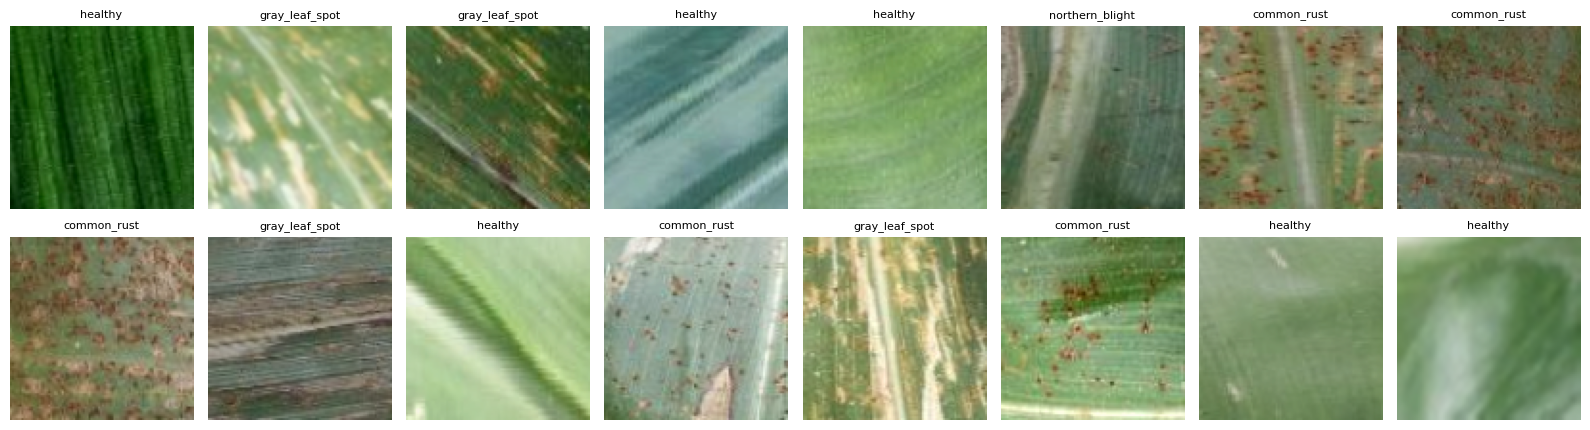

In [ ]:
# Ver que no haya fondo negro en un sample de imágenes
ds_check = PatchDataset(train_df, train=True)

viol = 0
for n in random.sample(range(len(ds_check)), 300):
    a = np.asarray(ds_check.raw(n))
    viol += (a.max(axis=2) < 30).mean() > 0.005 + 1e-9
assert viol == 0, f"{viol} recortes con más negro del permitido"
print("OK: 300 recortes de entrenamiento sin fondo negro")

def denorm(x):
    return (x.permute(1, 2, 0).numpy() * np.array(STD) + np.array(MEAN)).clip(0, 1)

fig, axes = plt.subplots(2, 8, figsize=(16, 4.5))
for ax, n in zip(axes.ravel(), random.sample(range(len(ds_check)), 16)):
    x, y, _ = ds_check[n]
    ax.imshow(denorm(x)); ax.axis("off"); ax.set_title(CLASSES[y], fontsize=8)
plt.tight_layout(); plt.show()

Ningún recorte revisado tiene más negro del permitido (0.5%).

# **<font color= #7aa8a7> Pesos de clase y cargadores </font>**
Para compensar el desbalance, la pérdida pesa más los errores de las clases con pocas imágenes. Los pesos se calculan **solo con train**.

In [ ]:
# La pérdida pesa más los errores en clases con pocas imágenes
counts = train_df["label"].value_counts().reindex(CLASSES)
weights = torch.tensor((len(train_df) / (len(CLASSES) * counts)).values, dtype=torch.float32)
print("pesos de clase:", {c: round(float(w), 2) for c, w in zip(CLASSES, weights)})
criterion = nn.CrossEntropyLoss(weight=weights.to(DEVICE))

train_ds = PatchDataset(train_df, train=True)
val_ds = PatchDataset(val_df, train=False)
test_ds = PatchDataset(test_df, train=False)
train_eval_ds = PatchDataset(train_df, train=False) # En modo eval solo para el RF

train_dl = DataLoader(train_ds, batch_size=BATCH, shuffle=True, num_workers=2, drop_last=True)
val_dl = DataLoader(val_ds, batch_size=128, shuffle=False, num_workers=2)
test_dl = DataLoader(test_ds, batch_size=128, shuffle=False, num_workers=2)

y_val = np.array(val_ds.labels)
y_test = np.array(test_ds.labels)
print(f"train {len(train_ds.paths)} imgs ({len(train_ds)} muestras/época) | "
      f"val {len(val_ds.paths)} imgs ({len(val_ds)} recortes) | "
      f"test {len(test_ds.paths)} imgs ({len(test_ds)} recortes)")

pesos de clase: {'common_rust': 0.8, 'gray_leaf_spot': 1.92, 'healthy': 0.8, 'northern_blight': 1.02}
train 2611 imgs (2611 muestras/época) | val 559 imgs (4355 recortes) | test 559 imgs (4374 recortes)


`gray_leaf_spot` pesa **1.92** y las clases grandes **0.8**, es decir, equivocarse en una gray cuesta más del doble. En validación y test hay unos 4,400 recortes cada uno (8 por imagen).

# **<font color= #7aa8a7> Referencia: Random Forest </font>**
Antes de entrenar una red neuronal primero entrenamos con un modelo de **referencia**, si la CNN no lo supera con claridad, no vale la pena toda la complejidad extra que se añade.

In [ ]:
# Funciones para evaluar por promedio las imágenes y el baseline
from sklearn.ensemble import RandomForestClassifier

RESULTS = {}

@torch.no_grad()
def predict_images(model, ds, dl):
    # probabilidad por imagen = promedio de las probabilidades de sus recortes
    model.eval()
    probs = np.zeros((len(ds.paths), len(CLASSES)))
    cnt = np.zeros(len(ds.paths))
    for x, _, i in dl:
        p = torch.softmax(model(x.to(DEVICE)), 1).cpu().numpy()
        for pi, ii in zip(p, i.numpy()):
            probs[ii] += pi; cnt[ii] += 1
    return probs / cnt[:, None]

def metrics(y, probs):
    pred = probs.argmax(1); labs = list(range(len(CLASSES)))
    return dict(acc=(pred == y).mean(), f1=f1_score(y, pred, average="macro"),
                recall=recall_score(y, pred, labels=labs, average=None),
                cm=confusion_matrix(y, pred, labels=labs), pred=pred)

def report(name, y, probs):
    m = metrics(y, probs); RESULTS[name] = m
    print(f"== {name}: accuracy {m['acc']:.3f} | macro-F1 {m['f1']:.3f}")
    print("   recall:", {c: round(r, 3) for c, r in zip(CLASSES, m["recall"])})
    print(pd.DataFrame(m["cm"], index=CLASSES, columns=CLASSES), "\n")
    return m

def hsv_hist(img):
    hsv = np.asarray(img.convert("HSV")).reshape(-1, 3)
    return np.concatenate([np.histogram(hsv[:, c], bins=16, range=(0, 256), density=True)[0] for c in range(3)])

def rf_features(ds):
    # histograma promedio de los recortes de cada imagen
    acc = {}
    for n in range(len(ds)):
        acc.setdefault(ds.items[n][0], []).append(hsv_hist(ds.raw(n)))
    return np.array([np.mean(acc[i], 0) for i in range(len(ds.paths))])

X_tr, X_va, X_te = rf_features(train_eval_ds), rf_features(val_ds), rf_features(test_ds)
rf = RandomForestClassifier(n_estimators=300, class_weight="balanced", n_jobs=-1, random_state=SEED)
rf.fit(X_tr, np.array(train_eval_ds.labels))
report("RF (val)", y_val, rf.predict_proba(X_va))
report("RF (test)", y_test, rf.predict_proba(X_te));

== RF (val): accuracy 0.877 | macro-F1 0.819
   recall: {'common_rust': np.float64(0.933), 'gray_leaf_spot': np.float64(0.432), 'healthy': np.float64(1.0), 'northern_blight': np.float64(0.887)}
                 common_rust  gray_leaf_spot  healthy  northern_blight
common_rust              167               6        3                3
gray_leaf_spot             9              32        0               33
healthy                    0               0      173                0
northern_blight            8               5        2              118 

== RF (test): accuracy 0.903 | macro-F1 0.861
   recall: {'common_rust': np.float64(0.949), 'gray_leaf_spot': np.float64(0.56), 'healthy': np.float64(0.994), 'northern_blight': np.float64(0.917)}
                 common_rust  gray_leaf_spot  healthy  northern_blight
common_rust              169               4        0                5
gray_leaf_spot             8              42        0               25
healthy                    1            

El Random Forest llega a **0.903 de accuracy y 0.861 de macro-F1** en test. Su problema es `gray_leaf_spot`: recall de **0.56**, porque la confunde con `northern_blight`. Con solo color no alcanza a distinguirlas; hace falta forma y textura.

# **<font color= #7aa8a7> CNN sencilla </font>**
La red tiene 4 bloques de dos convoluciones (32, 64, 128 y 192 filtros) con normalización por lotes, una capa de promedio global y *dropout* de 0.3 antes de la salida de 4 clases.

Se entrena con AdamW y una tasa de aprendizaje que baja suave (*cosine*), y se **guarda la mejor época según el F1 de validación**, con paro anticipado.

Cada época también mide el F1 de un subconjunto de train **sin aumentos**. La diferencia entre train y validación indica si hay **sobreajuste**.

ép 01 | loss 1.056 | val acc 0.436 | val F1 0.266 | recall gray 0.000 | recall northern 0.000 | 18s
       train(sin aumentos) F1 0.233 | brecha train-val -0.032
ép 02 | loss 0.818 | val acc 0.746 | val F1 0.709 | recall gray 0.770 | recall northern 0.429 | 19s
       train(sin aumentos) F1 0.739 | brecha train-val +0.030
ép 03 | loss 0.749 | val acc 0.784 | val F1 0.676 | recall gray 0.135 | recall northern 0.782 | 18s
       train(sin aumentos) F1 0.652 | brecha train-val -0.024
ép 04 | loss 0.682 | val acc 0.812 | val F1 0.782 | recall gray 0.635 | recall northern 0.797 | 17s
       train(sin aumentos) F1 0.796 | brecha train-val +0.014
ép 05 | loss 0.600 | val acc 0.832 | val F1 0.816 | recall gray 0.797 | recall northern 0.767 | 17s
       train(sin aumentos) F1 0.847 | brecha train-val +0.031
ép 06 | loss 0.554 | val acc 0.832 | val F1 0.711 | recall gray 0.108 | recall northern 0.977 | 17s
       train(sin aumentos) F1 0.663 | brecha train-val -0.049
ép 07 | loss 0.518 | val acc

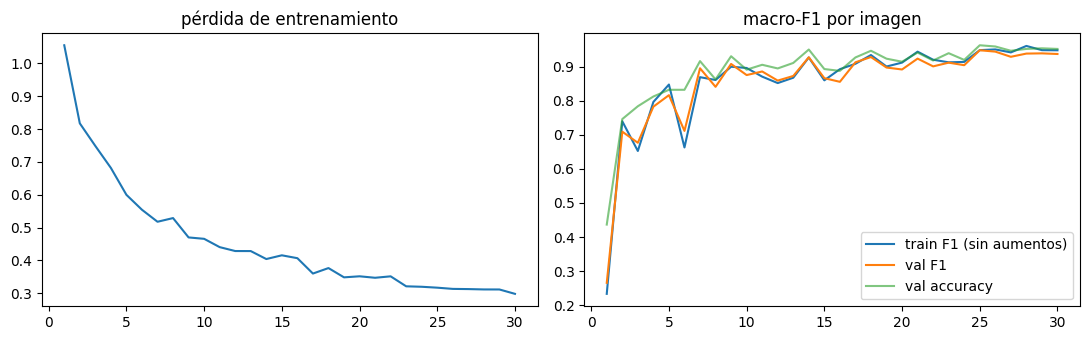

In [ ]:
# Se elige la mejor época por macro-F1 de VALIDACIÓN
def block(i, o):
    return nn.Sequential(
        nn.Conv2d(i, o, 3, padding=1, bias=False), nn.BatchNorm2d(o), nn.ReLU(inplace=True),
        nn.Conv2d(o, o, 3, padding=1, bias=False), nn.BatchNorm2d(o), nn.ReLU(inplace=True),
        nn.MaxPool2d(2))

class SmallCNN(nn.Module):
    def __init__(self, n_classes, p=0.3):
        super().__init__()
        self.features = nn.Sequential(block(3, 32), block(32, 64), block(64, 128), block(128, 192))
        self.head = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Dropout(p), nn.Linear(192, n_classes))
    def forward(self, x):
        return self.head(self.features(x))

# Subconjunto de train evaluado SIN aumentos y con el promedio de recortes por imagen
sub_df = pd.concat([g.sample(min(len(g), 120), random_state=0) for _, g in train_df.groupby("label")])
train_sub = PatchDataset(sub_df.reset_index(drop=True), train=False)
train_sub_dl = DataLoader(train_sub, batch_size=128, shuffle=False, num_workers=2)
y_trsub = np.array(train_sub.labels)

model = SmallCNN(len(CLASSES)).to(DEVICE)
opt = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)
sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=EPOCHS)
gi = CLASSES.index("gray_leaf_spot")
ni = CLASSES.index("northern_blight")

best_f1, bad, hist = -1.0, 0, []
for ep in range(1, EPOCHS + 1):
    t0 = time.time(); model.train(); tot, n = 0.0, 0
    for x, y, _ in train_dl:
        x, y = x.to(DEVICE), y.to(DEVICE)
        opt.zero_grad()
        loss = criterion(model(x), y)
        loss.backward(); opt.step()
        tot += loss.item() * len(y); n += len(y)
    sched.step()

    m = metrics(y_val, predict_images(model, val_ds, val_dl))                    # validación
    mt = metrics(y_trsub, predict_images(model, train_sub, train_sub_dl))        # train sin aumentos
    hist.append(dict(ep=ep, loss=tot / n, val_acc=m["acc"], val_f1=m["f1"], train_f1=mt["f1"]))
    print(f"ép {ep:02d} | loss {tot/n:.3f} | val acc {m['acc']:.3f} | val F1 {m['f1']:.3f} | "
          f"recall gray {m['recall'][gi]:.3f} | recall northern {m['recall'][ni]:.3f} | {time.time()-t0:.0f}s")
    print(f"       train(sin aumentos) F1 {mt['f1']:.3f} | brecha train-val {mt['f1'] - m['f1']:+.3f}")

    if m["f1"] > best_f1:
        best_f1, bad = m["f1"], 0
        torch.save(model.state_dict(), OUT / "cnn_base.pt")                      # en Drive: sobrevive a desconexiones
    else:
        bad += 1
        if bad >= PATIENCE:
            print("Parada temprana"); break

h = pd.DataFrame(hist)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].plot(h["ep"], h["loss"]); ax[0].set_title("pérdida de entrenamiento")
ax[1].plot(h["ep"], h["train_f1"], label="train F1 (sin aumentos)")
ax[1].plot(h["ep"], h["val_f1"], label="val F1")
ax[1].plot(h["ep"], h["val_acc"], label="val accuracy", alpha=0.6)
ax[1].set_title("macro-F1 por imagen"); ax[1].legend()
plt.tight_layout(); plt.show()

El F1 de validación sube con muchos altibajos. Gran parte del vaivén viene de la pareja `gray_leaf_spot` / `northern_blight`: cuando el recall de una sube, el de la otra baja (por ejemplo, en la época 6 gray cae a 0.11 y northern sube a 0.98). 

Hacia el final se estabiliza. La brecha entre train y validación se mantiene siempre **pequeña** (entre -0.05 y +0.04), sin separarse.

In [10]:
print(h.loc[h["val_f1"].idxmax(), ["ep", "val_f1", "val_acc", "train_f1"]])

ep          25.000000
val_f1       0.947807
val_acc      0.962433
train_f1     0.948129
Name: 24, dtype: float64


La mejor época es la **25**, con F1 de validación **0.948** y F1 de train de 0.948. La brecha es prácticamente **cero**, así que no hay sobreajuste visible.

# **<font color= #7aa8a7> Evaluación final en test </font>**
Aquí se mira el test **por primera vez**, con los pesos de la mejor época. Se compara con el Random Forest y se mide qué tan bien separa la pareja difícil (`gray_leaf_spot` contra `northern_blight`), frente a una regla que siempre responda "northern".

In [ ]:
# Cargar CNN pre-entrenada
model.load_state_dict(torch.load(OUT / "cnn_base.pt", map_location=DEVICE))   # en Drive, no en WORK
probs_te = predict_images(model, test_ds, test_dl)
m = report("CNN base (test)", y_test, probs_te)

# ¿cuántas gray/northern acierta, comparado con responder siempre northern?
gi, ni = CLASSES.index("gray_leaf_spot"), CLASSES.index("northern_blight")
mask = np.isin(y_test, [gi, ni])
print(f"Pareja gray/northern: acierto {(m['pred'][mask] == y_test[mask]).mean():.3f} | "
      f"siempre 'northern': {(y_test[mask] == ni).mean():.3f}")

# Tabla comparativa contra el RF
rows = {k: dict(accuracy=v["acc"], macro_F1=v["f1"], **{f"recall {c}": r for c, r in zip(CLASSES, v["recall"])})
        for k, v in RESULTS.items() if "test" in k}
print(pd.DataFrame(rows).T.round(3).to_string())

# Imágenes de test que NO se pudieron evaluar - no hay recorte válido
sin = meta[(meta["split"] == "test") & (meta["n_patch"] == 0)]
print(f"\nImágenes de test sin recorte (no evaluadas): {len(sin)}")
print(sin["label"].value_counts().to_string())

# Guardar la configuración junto al modelo (ya está en Drive)
(OUT / "cnn_base_config.json").write_text(json.dumps(
    dict(classes=CLASSES, patch=PATCH, img_size=IMG_SIZE, eval_k=EVAL_K, mean=MEAN, std=STD)))
print("Guardado en", OUT)

== CNN base (test): accuracy 0.952 | macro-F1 0.936
   recall: {'common_rust': np.float64(0.966), 'gray_leaf_spot': np.float64(0.867), 'healthy': np.float64(1.0), 'northern_blight': np.float64(0.917)}
                 common_rust  gray_leaf_spot  healthy  northern_blight
common_rust              172               1        0                5
gray_leaf_spot             0              65        1                9
healthy                    0               0      173                0
northern_blight            1              10        0              122 

Pareja gray/northern: acierto 0.899 | siempre 'northern': 0.639
                 accuracy  macro_F1  recall common_rust  recall gray_leaf_spot  recall healthy  recall northern_blight
RF (test)           0.903     0.861               0.949                  0.560           0.994                   0.917
CNN base (test)     0.952     0.936               0.966                  0.867           1.000                   0.917

Imágenes de test sin

**CNN sencilla en test: accuracy 0.952, macro-F1 0.936**, contra 0.903 y 0.861 del Random Forest. La mejora más grande está en `gray_leaf_spot`: el recall pasa de **0.56 a 0.867**.

El error que queda es el esperado: 9 gray se predicen northern y 10 northern se predicen gray. En esa pareja la red acierta **0.899**, contra 0.639 de la regla de siempre responder "northern".

**Limitación:** 19 imágenes de test (15 de `northern_blight`) no tienen recortes limpios y quedan fuera de esta evaluación.

# **<font color= #bb90ce> Parte 2: la variante a color </font>**
Se suben las fotos `color` y se agrega su ruta al ambiente. El split y las imágenes de cada conjunto son **exactamente los mismos** que con `segmented`.

In [ ]:
# Subir la version a color
from google.colab import files

COLOR_DIR = WORK / "raw"
if not COLOR_DIR.exists():
    up = files.upload()
    subprocess.run(["unzip", "-q", "-o", "/content/" + list(up.keys())[0], "-d", str(WORK)], check=True)

meta["path_color"] = [str(COLOR_DIR / l / k.split("/")[-1]) for l, k in zip(meta["label"], meta["s3_key"])]
assert all(Path(p).exists() for p in meta["path_color"]), "Faltan imágenes color"

# mismas imágenes usables y mismo orden que en T2 (así los pesos de clase y los splits no cambian)
usable_c = meta[meta["n_patch"] > 0].reset_index(drop=True)
train_c = usable_c[usable_c["split"] == "train"].reset_index(drop=True)
val_c = usable_c[usable_c["split"] == "val"].reset_index(drop=True)
test_c = usable_c[usable_c["split"] == "test"].reset_index(drop=True)
assert train_c["seg_key"].tolist() == train_df["seg_key"].tolist()
print("Mismas imágenes que en segmented:", len(train_c), len(val_c), len(test_c))

Se toman recortes de 96 px sobre una rejilla de 16 px en toda la imagen, **sin filtrar negro ni telón**. Es la única diferencia con el modelo anterior: ahora el fondo y la silueta de la hoja sí pueden entrar al recorte.

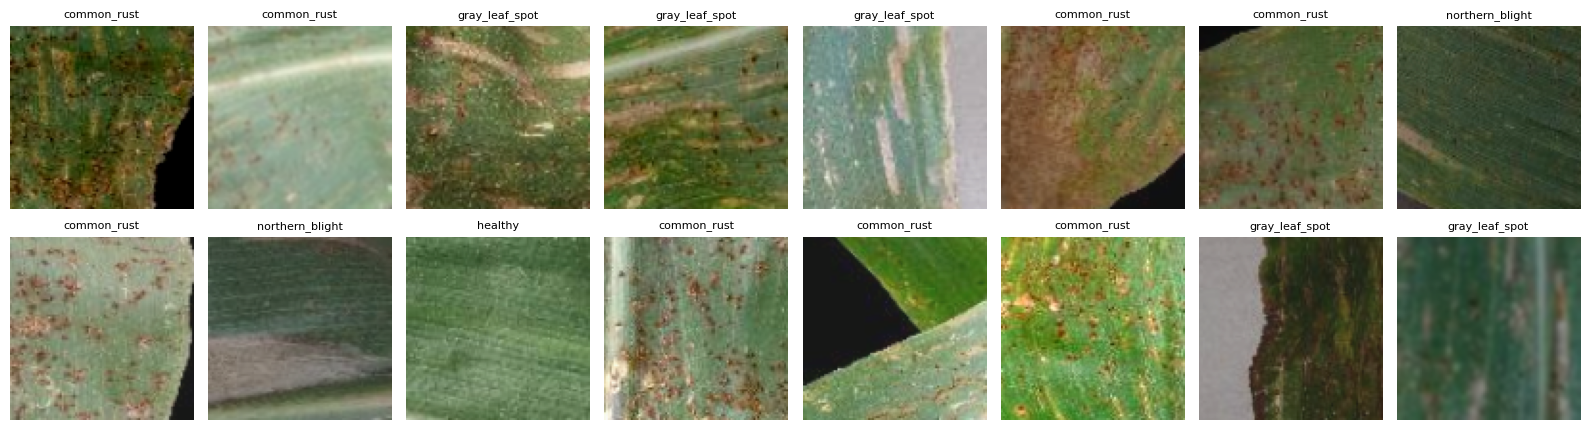

In [ ]:
ALL = np.array([(y, x) for y in range(0, 256 - PATCH + 1, 16) for x in range(0, 256 - PATCH + 1, 16)])

class ColorPatchDataset(PatchDataset):
    def __init__(self, df, train):
        self.paths = df["path_color"].tolist()
        self.keys = df["seg_key"].tolist()
        self.labels = [CLASS_TO_ID[l] for l in df["label"]]
        self.train = train
        self.tf = train_tf if train else eval_tf
        if train:
            self.items = [(i, None) for i in range(len(self.paths))]
        else:
            sel = np.unique(np.linspace(0, len(ALL) - 1, EVAL_K).round().astype(int))
            self.items = [(i, (int(ALL[j][0]), int(ALL[j][1]))) for i in range(len(self.paths)) for j in sel]

    def raw(self, n):
        i, box = self.items[n]
        if box is None:
            j = random.randrange(len(ALL)); box = (int(ALL[j][0]), int(ALL[j][1]))
        y, x = box
        return Image.open(self.paths[i]).convert("RGB").crop((x, y, x + PATCH, y + PATCH))

train_ds_c, val_ds_c, test_ds_c = (ColorPatchDataset(train_c, True), ColorPatchDataset(val_c, False),
                                   ColorPatchDataset(test_c, False))
train_dl_c = DataLoader(train_ds_c, batch_size=BATCH, shuffle=True, num_workers=2, drop_last=True)
val_dl_c = DataLoader(val_ds_c, batch_size=128, shuffle=False, num_workers=2)
test_dl_c = DataLoader(test_ds_c, batch_size=128, shuffle=False, num_workers=2)

# Recortes de entrenamiento
fig, axes = plt.subplots(2, 8, figsize=(16, 4.5))
for ax, n in zip(axes.ravel(), random.sample(range(len(train_ds_c)), 16)):
    x, y, _ = train_ds_c[n]
    ax.imshow(denorm(x)); ax.axis("off"); ax.set_title(CLASSES[y], fontsize=8)
plt.tight_layout(); plt.show()

# **<font color= #bb90ce> Entrenar la CNN a color </font>**
Misma arquitectura, mismo optimizador, mismas épocas y misma paciencia que la corrida anterior.

In [ ]:
# cualquier diferencia de resultados se debe a los datos, no al modelo
def fit(tag, tr_dl, va_ds, va_dl, y_va):
    torch.manual_seed(SEED); random.seed(SEED)
    net = SmallCNN(len(CLASSES)).to(DEVICE)
    opt = torch.optim.AdamW(net.parameters(), lr=1e-3, weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=EPOCHS)
    best, bad = -1.0, 0
    for ep in range(1, EPOCHS + 1):
        t0 = time.time(); net.train(); tot, n = 0.0, 0
        for x, y, _ in tr_dl:
            x, y = x.to(DEVICE), y.to(DEVICE)
            opt.zero_grad(); loss = criterion(net(x), y); loss.backward(); opt.step()
            tot += loss.item() * len(y); n += len(y)
        sched.step()
        m = metrics(y_va, predict_images(net, va_ds, va_dl))
        print(f"[{tag}] ép {ep:02d} | loss {tot/n:.3f} | val acc {m['acc']:.3f} | val F1 {m['f1']:.3f} | {time.time()-t0:.0f}s")
        if m["f1"] > best:
            best, bad = m["f1"], 0
            torch.save(net.state_dict(), OUT / f"cnn_{tag}.pt")
        else:
            bad += 1
            if bad >= PATIENCE:
                print("Parada temprana"); break
    net.load_state_dict(torch.load(OUT / f"cnn_{tag}.pt", map_location=DEVICE))
    return net, best

net_c, best_c = fit("color", train_dl_c, val_ds_c, val_dl_c, np.array(val_ds_c.labels))
print(f"\nMejor val F1 (color): {best_c:.3f}")

[color] ép 01 | loss 0.992 | val acc 0.564 | val F1 0.363 | 13s
[color] ép 02 | loss 0.777 | val acc 0.807 | val F1 0.761 | 14s
[color] ép 03 | loss 0.695 | val acc 0.889 | val F1 0.825 | 13s
[color] ép 04 | loss 0.655 | val acc 0.800 | val F1 0.725 | 12s
[color] ép 05 | loss 0.585 | val acc 0.801 | val F1 0.779 | 11s
[color] ép 06 | loss 0.548 | val acc 0.887 | val F1 0.823 | 13s
[color] ép 07 | loss 0.539 | val acc 0.884 | val F1 0.846 | 13s
[color] ép 08 | loss 0.491 | val acc 0.914 | val F1 0.856 | 12s
[color] ép 09 | loss 0.479 | val acc 0.925 | val F1 0.898 | 13s
[color] ép 10 | loss 0.461 | val acc 0.941 | val F1 0.920 | 12s
[color] ép 11 | loss 0.439 | val acc 0.945 | val F1 0.923 | 12s
[color] ép 12 | loss 0.406 | val acc 0.925 | val F1 0.902 | 13s
[color] ép 13 | loss 0.385 | val acc 0.953 | val F1 0.935 | 13s
[color] ép 14 | loss 0.412 | val acc 0.955 | val F1 0.932 | 13s
[color] ép 15 | loss 0.421 | val acc 0.957 | val F1 0.939 | 13s
[color] ép 16 | loss 0.385 | val acc 0.9

El entrenamiento termina con un mejor F1 de validación de **0.955** (contra 0.948 de la CNN limpia).

# **<font color= #bb90ce> Test y comparación </font>**
Ahora compararemos los 3 modelos entrenados, el baseline, la CNN simple segmentada y la CNN simple a color para poder analizar las diferencias entre los resultados y en que áreas existen fallas o grietas:

In [ ]:
# Tabla comparativa
y_test_c = np.array(test_ds_c.labels)
report("CNN color (test)", y_test_c, predict_images(net_c, test_ds_c, test_dl_c))

rows = {k: dict(accuracy=v["acc"], macro_F1=v["f1"], **{f"recall {c}": r for c, r in zip(CLASSES, v["recall"])})
        for k, v in RESULTS.items() if "test" in k}
print(pd.DataFrame(rows).T.round(3).to_string())

== CNN color (test): accuracy 0.966 | macro-F1 0.951
   recall: {'common_rust': np.float64(0.994), 'gray_leaf_spot': np.float64(0.893), 'healthy': np.float64(1.0), 'northern_blight': np.float64(0.925)}
                 common_rust  gray_leaf_spot  healthy  northern_blight
common_rust              177               1        0                0
gray_leaf_spot             1              67        0                7
healthy                    0               0      173                0
northern_blight            0              10        0              123 

                  accuracy  macro_F1  recall common_rust  recall gray_leaf_spot  recall healthy  recall northern_blight
RF (test)            0.903     0.861               0.949                  0.560           0.994                   0.917
CNN base (test)      0.952     0.936               0.966                  0.867           1.000                   0.917
CNN color (test)     0.966     0.951               0.994                  0.893  

**CNN a color: accuracy 0.966, macro-F1 0.951**, un poco mejor que la limpia (0.936). Si solo miráramos esta tabla, ganaría la de color.

Pero la diferencia puede deberse a que **ve el fondo**, hay que comprobar este escenario:

# **<font color= #bb90ce> Evaluación cruzada </font>**
Si la red de color depende del fondo, debería **caer** al ver solo tejido limpio. Y la red limpia debería caer menos con recortes de color.

In [ ]:
net_s = SmallCNN(len(CLASSES)).to(DEVICE)
net_s.load_state_dict(torch.load(OUT / "cnn_base.pt", map_location=DEVICE))
assert test_df["seg_key"].tolist() == test_c["seg_key"].tolist()      # mismas imágenes, mismo orden

cells = {
    ("segmented", "tejido limpio"): predict_images(net_s, test_ds, test_dl),
    ("segmented", "recortes color"): predict_images(net_s, test_ds_c, test_dl_c),
    ("color", "tejido limpio"): predict_images(net_c, test_ds, test_dl),
    ("color", "recortes color"): predict_images(net_c, test_ds_c, test_dl_c),
}
rows = []
for (train_v, eval_v), p in cells.items():
    m = metrics(y_test, p)
    rows.append(dict(entrenado_con=train_v, evaluado_con=eval_v, macro_F1=m["f1"],
                     **{f"recall {c}": r for c, r in zip(CLASSES, m["recall"])}))
print(pd.DataFrame(rows).round(3).to_string(index=False))

entrenado_con   evaluado_con  macro_F1  recall common_rust  recall gray_leaf_spot  recall healthy  recall northern_blight
    segmented  tejido limpio     0.936               0.966                  0.867             1.0                   0.917
    segmented recortes color     0.890               0.910                  0.880             1.0                   0.789
        color  tejido limpio     0.862               0.944                  0.787             1.0                   0.722
        color recortes color     0.951               0.994                  0.893             1.0                   0.925


| Entrenado con | Evaluado con | macro-F1 |
|---|---|---|
| segmented | tejido limpio | 0.936 |
| segmented | recortes color | 0.890 |
| color | tejido limpio | **0.862** |
| color | recortes color | 0.951 |

- La CNN de color **cae de 0.951 a 0.862** cuando ya no puede ver el fondo. Parte de su buen resultado dependía de él.
- La CNN limpia cae menos (0.936 → 0.890) y **mantiene un mejor resultado en tejido limpio** que la de color.
- `northern_blight` es la clase que más se afecta en la de color (recall de 0.925 a 0.722).

**Conclusión:** la CNN a color puntúa más alto en el test de PlantVillage, pero es **menos confiable** con fotos donde el fondo sea distinto. Por eso se prefiere entrenar con tejido limpio. Esto también anticipa que las métricas de PlantVillage serán más optimistas que el desempeño en campo.